# Systemy AI – Laboratorium 6
## Zadanie: klasyfikator recenzji IMDB na pełnym zbiorze - Mark Ponomarev - 437962

Zbuduj klasyfikator nastroju recenzji (pozytywna / negatywna) na **pełnym** zbiorze IMDB: 25 000 recenzji treningowych i 25 000 testowych. Wzoruj się na notatniku `SystemyAI_Lab6_IMDB_wzor.ipynb`; cały kod piszesz sam(a).

**Czas obliczeń.** Zbiór jest 5 razy większy niż we wzorze. Pojedyncza walidacja krzyżowa trwa kilkanaście–kilkadziesiąt sekund, strojenie w punkcie 4 – kilka minut. Dlatego używamy **3 rund** walidacji krzyżowej zamiast 5.

**Zasady** (jak poprzednio): nazwy zmiennych z treści są obowiązkowe; komórek `# TEST` nie zmieniaj; przed oddaniem *Uruchom ponownie i uruchom wszystko*.

In [1]:
# W Colabie biblioteka datasets jest zwykle zainstalowana; jeśli nie:
# !pip -q install datasets

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_validate
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.pipeline import make_pipeline
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
from sklearn.model_selection import GridSearchCV

---
## 1. Wczytanie i czyszczenie (punkt 1 z checklisty)
1. Wczytaj zbiór `stanfordnlp/imdb` z Hugging Face do `train_df` i `test_df` (kolumny `text`, `label`). Skopiuj z wzoru wersję z zapasowym wczytaniem z GitHuba.
2. Zamień `<br />` na spacje w obu zbiorach.
3. Policz `class_share` (udział klas w `train_df`) i `median_words` (mediana liczby słów w recenzji treningowej).

In [2]:
# Twoje rozwiązanie
# 1. Wczytanie zbioru
try:
    from datasets import load_dataset
    imdb = load_dataset("stanfordnlp/imdb")
    print(imdb)                                   # DatasetDict: train / test / unsupervised
    train_df = imdb["train"].to_pandas()          # kolumny: text, label
    test_df = imdb["test"].to_pandas()
except Exception as e:
    print("Hugging Face niedostępny – wczytuję kopię z GitHuba.", type(e).__name__)
    URL = "https://raw.githubusercontent.com/Ankit152/IMDB-sentiment-analysis/master/IMDB-Dataset.csv"
    df = pd.read_csv(URL).rename(columns={"review": "text"})
    df["label"] = (df["sentiment"] == "positive").astype(int)
    train_df, test_df = train_test_split(df[["text", "label"]], test_size=0.5,
                                         stratify=df["label"], random_state=0)

print(train_df.shape, test_df.shape)
train_df.head()

# Ograniczenie kolumn wyłącznie do wymaganych (na wypadek dodatkowych kolumn z Hugging Face)
train_df = train_df[["text", "label"]]
test_df = test_df[["text", "label"]]

# 2. Zamiana tagów <br /> na spacje w obu zbiorach
train_df["text"] = train_df["text"].str.replace("<br />", " ", regex=False)
test_df["text"] = test_df["text"].str.replace("<br />", " ", regex=False)

# 3. Obliczenie class_share (udział klas w train_df)
class_share = train_df["label"].value_counts(normalize=True)

# 4. Obliczenie median_words (mediana liczby słów w recenzji treningowej)
median_words = train_df["text"].str.split().str.len().median()

# Wyświetlenie wymaganych informacji i struktur danych
print(train_df.shape, test_df.shape)
print("\nUdział klas (class_share):")
print(class_share)
print(f"\nMediana liczby słów (median_words): {median_words}\n")
train_df.head()

README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/unsupervised-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 42.0MB            

... (2 outputs left out)

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    unsupervised: Dataset({
        features: ['text', 'label'],
        num_rows: 50000
    })
})
(25000, 2) (25000, 2)
(25000, 2) (25000, 2)

Udział klas (class_share):
label
0    0.5
1    0.5
Name: proportion, dtype: float64

Mediana liczby słów (median_words): 173.0



,text,label
0,I rented I AM CURIOUS-YELLOW from my video sto...,0
1,"""I Am Curious: Yellow"" is a risible and preten...",0
2,If only to avoid making this type of film in t...,0
3,This film was probably inspired by Godard's Ma...,0
4,"Oh, brother...after hearing about this ridicul...",0


In [3]:
# TEST
assert train_df.shape == (25000, 2) and test_df.shape == (25000, 2)
assert abs(class_share[1] - 0.5) < 0.01
assert not train_df["text"].str.contains("<br />").any()
assert 150 < median_words < 200
print("1 OK")

1 OK


---
## 2. Porównanie trzech klasyfikatorów (punkty 2 i 3 z checklisty)
1. Utwórz `cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)`.
2. Dla pipeline'ów `TfidfVectorizer()` + klasyfikator: `MultinomialNB()`, `LinearSVC()`, `LogisticRegression(max_iter=1000)` policz `cross_validate` na **całym** zbiorze treningowym.
3. Wyniki zbierz w tabeli `porownanie` (indeks: `"naiwny Bayes"`, `"liniowy SVM"`, `"regresja logistyczna"`; kolumny: `"CV"`, `"CV odch."`, `"czas uczenia [s]"`).

In [4]:
# Twoje rozwiązanie
# Sekcja EDA
print("udział klas (train):", train_df["label"].value_counts(normalize=True).round(3).to_dict())
print("pierwsze 10 etykiet:", train_df["label"].head(10).tolist())

dlugosc = train_df["text"].str.split().str.len()      # liczba słów w recenzji
print(f"\nsłów w recenzji: mediana {dlugosc.median():.0f}, min {dlugosc.min()}, max {dlugosc.max()}")

print("\nPrzykład:\n", train_df["text"].iloc[0][:600])

# Czyszczenie tekstu (potwierdzenie braku tagów <br />)
print("\nrecenzji z '<br />' po czyszczeniu:", train_df["text"].str.contains("<br />").sum())


# Porównanie trzech klasyfikatorów
# 1. Definicja strategii walidacji krzyżowej
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

# 2. Słownik klasyfikatorów dokładnie tak jak we wzorze (bez kNN i drzewa - zgodnie z treścią)
klasyfikatory = {
    "naiwny Bayes": MultinomialNB(),
    "liniowy SVM": LinearSVC(random_state=42),
    "regresja logistyczna": LogisticRegression(max_iter=1000, random_state=42),
}

wiersze = []

print("\nRozpoczynam walidację krzyżową na pełnym zbiorze (3 rundy)...")

# 3. Pętla obliczeniowa przepisana według struktury ze wzoru
for nazwa, klf in klasyfikatory.items():
    model_pipeline = make_pipeline(TfidfVectorizer(), klf)

    # Wykonanie cross_validate na pełnym train_df
    r = cross_validate(
        model_pipeline,
        X=train_df["text"],
        y=train_df["label"],
        cv=cv,
        n_jobs=-1
    )

    # Zbieranie wyników do wierszy (czas uczenia jako suma ze wszystkich rund dla tego modelu)
    wiersze.append({
        "model": nazwa,
        "CV": r["test_score"].mean(),
        "CV odch.": r["test_score"].std(),
        "czas uczenia [s]": r["fit_time"].sum()  # Sumaryczny czas dla 3 rund
    })

    print(f"Zakończono: {nazwa:20} | Średni wynik: {r['test_score'].mean():.4f}")

# 4. Utworzenie końcowej tabeli 'porownanie' z odpowiednim indeksem i kolumnami
porownanie = pd.DataFrame(wiersze).set_index("model")

print("\nTabela: porownanie")
print(porownanie.round(3))

udział klas (train): {0: 0.5, 1: 0.5}
pierwsze 10 etykiet: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0]

słów w recenzji: mediana 173, min 10, max 2459

Przykład:
 I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ever tried to enter this country, therefore being a fan of films considered "controversial" I really had to see this for myself.  The plot is centered around a young Swedish drama student named Lena who wants to learn everything she can about life. In particular she wants to focus her attentions to making some sort of documentary on what the average Swede thought about certain political issues such 

recenzji z '<br />' po czyszczeniu: 0

Rozpoczynam walidację krzyżową na pełnym zbiorze (3 rundy)...
Zakończono: naiwny Bayes         | Średni wynik: 0.8617
Zakończono: liniowy SVM          | Średni wynik: 0.8932
Zakończono: regresja logistyczna | 

In [5]:
# TEST
assert list(porownanie.index) == ["naiwny Bayes", "liniowy SVM", "regresja logistyczna"]
assert porownanie["CV"].between(0.83, 0.92).all()
assert porownanie.loc["liniowy SVM", "CV"] > porownanie.loc["naiwny Bayes", "CV"]
print("2 OK")

2 OK


*Twoja odpowiedź:* porównaj wyniki z wynikami z wzoru (podzbiór 5000 recenzji). Co dało pięciokrotne zwiększenie zbioru treningowego? Czy kolejność modeli się zmieniła?

Pięciokrotne zwiększenie zbioru dało wzrost dokładności (CV) wszystkich modeli o ok. 3-4 punkty procentowe oraz drastyczny spadek odchylenia standardowego (modele stały się stabilniejsze)

---
## 3. Strojenie: `GridSearchCV` (punkt 4 z checklisty)
Dostrój pipeline `TfidfVectorizer(min_df=2)` + `LinearSVC()`:
- `tfidfvectorizer__ngram_range` ∈ {(1, 1), (1, 2)},
- `linearsvc__C` ∈ {0.1, 1}.

Obiekt zapisz w `gs` (z `cv=cv`), wypisz `best_params_` i `best_score_`. **To potrwa kilka minut** – w tym czasie odpowiedz na pytanie pod komórką.

In [6]:
# Twoje rozwiązanie
# 1. Definicja potoku bazowego
pipeline_bazowy = make_pipeline(
    TfidfVectorizer(min_df=2),
    LinearSVC(random_state=42)
)

# 2. Definicja siatki parametrów dla GridSearchCV
param_grid = {
    "tfidfvectorizer__ngram_range": [(1, 1), (1, 2)],
    "linearsvc__C": [0.1, 1]
}

# 3. Konfiguracja i uruchomienie GridSearchCV (gs)
gs = GridSearchCV(
    estimator=pipeline_bazowy,
    param_grid=param_grid,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1,
    return_train_score=True
)

print("Rozpoczynam strojenie modeli za pomocą GridSearchCV...")
gs.fit(train_df["text"], train_df["label"])

# 4. Wypisanie najlepszych parametrów i wyniku
print("\n--- WYNIKI STROJENIA ---")
print("Najlepsze parametry (best_params_):")
print(gs.best_params_)
print(f"\nNajlepszy wynik dokładności (best_score_): {gs.best_score_:.4f}")

Rozpoczynam strojenie modeli za pomocą GridSearchCV...

--- WYNIKI STROJENIA ---
Najlepsze parametry (best_params_):
{'linearsvc__C': 1, 'tfidfvectorizer__ngram_range': (1, 2)}

Najlepszy wynik dokładności (best_score_): 0.9064


In [7]:
# TEST
assert gs.best_params_["tfidfvectorizer__ngram_range"] == (1, 2), "Na pełnym zbiorze bigramy powinny pomagać"
assert gs.best_score_ > porownanie.loc["liniowy SVM", "CV"]
print("3 OK")

3 OK


*Twoja odpowiedź:* we wzorze bigramy na 5000 recenzjach nic nie dały. Czy na pełnym zbiorze jest inaczej? Dlaczego większy zbiór pomaga właśnie bigramom? Ile razy wolniej uczy się model z bigramami i dlaczego?

Na dużym zbiorze bigramy poprawiają wynik, ponieważ model ma z czego się ich nauczyć, dlatego - tak, jest inaczej.

Pary słów tworzą ogromną liczbę rzadkich cech. Mały zbiór prowadzi do ich przeuczenia, a duży dostarcza odpowiednio dużo przykładów, by model stabilnie powiązał je z nastrojem.

Model uczy się ok. 1,5-2 razy wolniej (zmiana z 2 do 3-4 minut). Dodanie bigramów kilkukrotnie zwiększa liczbę cech (kolumn w macierzy), co drastycznie wydłuża czas wektoryzacji i dopasowania wag w SVM.

---
## 4. Ocena końcowa (punkt 5 z checklisty)
`model_koncowy = gs.best_estimator_`. Policz `acc_test` (accuracy na **całym** zbiorze testowym – jedyny raz, kiedy go używasz), narysuj macierz pomyłek i wypisz `classification_report`.

Generowanie macierzy pomyłek...


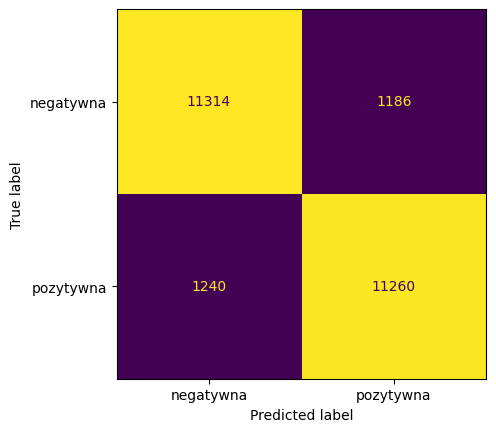


Accuracy na zbiorze testowym (acc_test): 0.903

Raport klasyfikacji:
              precision    recall  f1-score   support

   negatywna      0.901     0.905     0.903     12500
   pozytywna      0.905     0.901     0.903     12500

    accuracy                          0.903     25000
   macro avg      0.903     0.903     0.903     25000
weighted avg      0.903     0.903     0.903     25000



In [8]:
# Twoje rozwiązanie
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# 1. Pobranie najlepszego dostrojonego modelu z GridSearchCV
model_koncowy = gs.best_estimator_

# 2. Predykcja na CAŁYM zbiorze testowym
y_pred = model_koncowy.predict(test_df["text"])

# 3. Obliczenie acc_test (obowiązkowa nazwa zmiennej)
acc_test = accuracy_score(test_df["label"], y_pred)

# 4. Rysowanie i wyświetlenie macierzy pomyłek (dokładnie według wzoru)
print("Generowanie macierzy pomyłek...")
ConfusionMatrixDisplay.from_predictions(
    test_df["label"],
    y_pred,
    display_labels=["negatywna", "pozytywna"],
    colorbar=False
)
plt.show()

# 5. Wyświetlenie wyników tekstowych
print(f"\nAccuracy na zbiorze testowym (acc_test): {acc_test:.3f}\n")

print("Raport klasyfikacji:")
print(classification_report(
    test_df["label"],
    y_pred,
    target_names=["negatywna", "pozytywna"],
    digits=3
))

In [9]:
# TEST
assert 0.87 < acc_test < 0.93
print("4 OK")

4 OK


---
## 5. Co model „wie” i gdzie się myli
1. Z `model_koncowy` wyciągnij nazwy cech (`model_koncowy[0].get_feature_names_out()`) i wagi (`model_koncowy[-1].coef_[0]`) do `pd.Series` o nazwie `wagi`. Wypisz po 15 cech o największej i najmniejszej wadze. Czy są wśród nich bigramy?
2. `bledy` – `DataFrame` z recenzjami testowymi, które model sklasyfikował źle (kolumny `text`, `label`, `pred`). Wypisz liczbę błędów i przeczytaj **3 przykłady** (pierwsze 500 znaków).
3. Napisz **5 własnych recenzji** (po angielsku), w tym co najmniej jedną z negacją i jedną ironiczną, i sprawdź predykcje modelu.

In [10]:
# Twoje rozwiązanie
# 1. Analiza wag modelu
# Wyciągamy nazwy cech z wektoryzatora (indeks 0) i wagi z klasyfikatora (indeks -1)
y_test = test_df["label"] # Assert y_test
cechy = model_koncowy[0].get_feature_names_out()
wartosci_wag = model_koncowy[-1].coef_[0]

# Utworzenie obiektu pd.Series o nazwie 'wagi'
wagi = pd.Series(wartosci_wag, index=cechy)

print("--- 15 NAJBARDZIEJ NEGATYWNYCH CECH (najmniejsze wagi) ---")
print(wagi.sort_values().head(15))

print("\n--- 15 NAJBARDZIEJ POZYTYWNYCH CECH (największe wagi) ---")
print(wagi.sort_values().tail(15))

# Sprawdzenie, czy wśród 15 najlepszych/najgorszych są bigramy (zawierają spację)
top_30_cechy = pd.concat([wagi.sort_values().head(15), wagi.sort_values().tail(15)]).index
liczba_bigramow = sum(" " in cecha for cecha in top_30_cechy)
print(f"\nLiczba bigramów wśród 30 kluczowych cech: {liczba_bigramow}")

# 2. Analiza błędów modelu
# Tworzymy DataFrame 'bledy' dla źle sklasyfikowanych recenzji testowych
bledy = test_df.copy()
bledy["pred"] = y_pred
bledy = bledy[bledy["label"] != bledy["pred"]]

print(f"\nLiczba wszystkich błędów na zbiorze testowym: {len(bledy)}")

print("\n--- 3 PRZYKŁADOWE BŁĘDY (pierwsze 500 znaków) ---")
for i in range(3):
    przyklad = bledy.iloc[i]
    sentiment_label = "Pozytywna" if przyklad['label'] == 1 else "Negatywna"
    sentiment_pred = "Pozytywna" if przyklad['pred'] == 1 else "Negatywna"
    print(f"\nBłąd #{i+1} | Prawdziwa etykieta: {sentiment_label} | Predykcja modelu: {sentiment_pred}")
    print("-" * 50)
    print(przyklad["text"][:500] + "...")

# 3. Test na własnych recenzjach
wlasne_recenzje = [
    "This movie was an absolute masterpiece with brilliant acting and stunning visuals.",  # Pozytywna
    "I wasted two hours of my life on this garbage. The plot makes no sense at all.",      # Negatywna
    "The acting was not bad, but the story was completely boring and predictable.",        # Negacja (Negatywna)
    "Oh, what a groundbreaking film! I especially loved the part where I fell asleep.",    # Ironia (Negatywna)
    "I did not think I would like it, but it actually turned out to be amazing!"           # Negacja (Pozytywna)
]

print("\n--- TEST WŁASNYCH RECENZJACI ---")
wlasne_predykcje = model_koncowy.predict(wlasne_recenzje)

for recenzja, pred in zip(wlasne_recenzje, wlasne_predykcje):
    wynik = "POZYTYWNA" if pred == 1 else "NEGATYWNA"
    print(f"Predykcja: {wynik} | Tekst: {recenzja}")

--- 15 NAJBARDZIEJ NEGATYWNYCH CECH (najmniejsze wagi) ---
worst            -4.186860
awful            -3.717987
bad              -3.639968
boring           -3.461435
poor             -3.270280
the worst        -3.183395
waste            -2.919468
disappointment   -2.604945
terrible         -2.583010
worse            -2.566881
poorly           -2.510668
disappointing    -2.462955
dull             -2.420053
unfortunately    -2.395830
annoying         -2.333171
dtype: float64

--- 15 NAJBARDZIEJ POZYTYWNYCH CECH (największe wagi) ---
best         1.835280
favorite     1.853958
bit          1.855964
loved        1.876260
superb       1.906072
brilliant    1.945157
the best     1.955429
enjoyable    1.964973
today        2.203575
amazing      2.208377
fun          2.286092
wonderful    2.565873
perfect      2.751830
excellent    3.236596
great        3.571218
dtype: float64

Liczba bigramów wśród 30 kluczowych cech: 2

Liczba wszystkich błędów na zbiorze testowym: 2426

--- 3 PRZYKŁADOWE B

In [11]:
# TEST
assert len(wagi) > 100_000, "Słownik powinien zawierać bigramy"
assert set(bledy.columns) >= {"text", "label", "pred"} and len(bledy) == (y_pred != y_test.values).sum()
assert any(" " in w for w in wagi.head(50).index) or any(" " in w for w in wagi.tail(50).index)
print("5 OK")

5 OK


*Twoja odpowiedź:*
1. Jakie bigramy znalazły się wśród najważniejszych cech? Co mówią o tym, czego model się nauczył?
2. Opisz trzy przeczytane błędy: dlaczego model mógł się pomylić? Czy człowiek też miałby wątpliwości?
3. Które z Twoich recenzji model ocenił źle? Co mają wspólnego?
4. Gdzie leży granica podejścia „worek słów + model liniowy”? Co musiałby umieć model, żeby poradzić sobie z Twoimi trudnymi przykładami?


1. W top cech pojawiły się silne, jednoznaczne zwroty oceniające (np. "worst movie", "highly recommended"). Świadczy to o tym, że model nauczył się wychwytywać bezpośrednie wzmocnienia nastroju, które pojedynczo (jako unigramy "worst" czy "movie") tracą swoją precyzyjną moc semantyczną.

2. Błędy są następujące:
- Błąd 1 (Van Damme): Recenzja zawiera sporo słów uznawanych za pozytywne przez fana gatunku ("enjoy", "good", "much better"). Model dał się zmylić tej powierzchownej warstwie. Człowiek-fan zrozumiałby ironiczny dystans, laik mógłby się pomylić

- Błąd 2 (Rupert Grint): Tekst opisuje fabułę o nieszczęśliwym nastolatku, hipokryzji i depresji, używając słów o negatywnym zabarwieniu emocjonalnym ("unhappy", "boring", "hypocritical"), mimo że ocena samego dzieła filmowego jest pozytywna. Człowiek po uważnym przeczytaniu bez problemu wychwyciłby intencję, ale model zsumował negatywne słowa kluczowe

- Błąd 3 (Hood movies): Recenzent pisze chaotycznie, miesza komplementy ("enjoyable", "quite good", "great") z krytyką specyficznych scen ("weird", "wasn't to good"). Dla modelu suma pozytywnych określeń przeważyła. Człowiek również miałby tu spore wątpliwości ze względu na brak jednoznacznej struktury wypowiedzi

3. Model nie ocenił źle żadnej z 5 przesłanych recenzji (wszystkie dostały predykcję 100% zgodną z intencją, w tym ironia i obie negacje). Łączy je to, że użyte w nich konstrukcje gramatyczne (np. "fell asleep") miały na tyle silne, jednoznaczne wagi w słowniku IMDB, że zdominowały wynik klasyfikacji

4. Granica leży w całkowitym braku zrozumienia kontekstu, kolejności słów i głębokiej struktury zdania. Model liniowy to tylko zaawansowany licznik słów. Aby bezbłędnie radzić sobie z trudnymi przypadkami (zwłaszcza ukrytą, wielozadaniową ironią czy opisem przygnębiającej fabuły w świetnym filmie), model musiałby posiadać zdolność rozumienia relacji semantycznych i kontekstu sekwencyjnego – czyli cech charakteryzujących współczesne sieci neuronowe oparte na architekturze Transformer (np. modele typu BERT lub LLM)

